# Практична робота №2

## Зниження розмірності, кластеризація та класифікація текстів

**Мета:** дослідити зниження розмірності, кластеризацію та базову класифікацію текстів засобами Scikit-learn.

У частинах 1–2 використано той самий датасет **Spambase**, що й у практичній роботі №1. Він містить 57 числових характеристик електронних листів і бінарну мітку `spam`. Для частини 3 використано **SMS Spam Collection** з UCI: на відміну від Spambase, цей набір містить початкові тексти повідомлень.

Під час кластеризації стовпець `spam` не використовую. Він потрібен тільки наприкінці, щоб порівняти кластери зі справжніми класами.

## 0. Імпорти та налаштування

In [1]:
from pathlib import Path
from time import perf_counter
from statistics import median
import re
import string
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from wordcloud import WordCloud

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, normalized_mutual_info_score, precision_score,
    recall_score, silhouette_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 67
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 80)

# Ноутбук працює і при запуску з pr2, і при запуску з кореня репозиторію.
CWD = Path.cwd()
PR2_DIR = CWD if (CWD / "sms_data").exists() else CWD / "pr2"
SPAMBASE_PATH = PR2_DIR.parent / "pr1" / "spambase.csv"
SMS_PATH = PR2_DIR / "sms_data" / "SMSSpamCollection"

print("Spambase:", SPAMBASE_PATH.resolve())
print("SMS:", SMS_PATH.resolve())

Spambase: C:\Users\serya\study\magesty\IAD\pr1\spambase.csv
SMS: C:\Users\serya\study\magesty\IAD\pr2\sms_data\SMSSpamCollection


## 1. Зниження розмірності та візуалізація

### 1.1. Завантаження й очищення Spambase

Повторюю правила з Lab 1: видаляю повні дублікати, а потім рядки з однаковими 57 ознаками, але різними мітками. Це дає той самий набір із 4204 унікальних і несуперечливих прикладів.

In [2]:
df_raw = pd.read_csv(SPAMBASE_PATH)
features = df_raw.columns.drop("spam").tolist()

print("Початковий розмір:", df_raw.shape)
print("Пропусків:", int(df_raw.isna().sum().sum()))
print("Повних дублікатів:", int(df_raw.duplicated().sum()))

df = df_raw.drop_duplicates().copy()
conflict = df.groupby(features)["spam"].transform("nunique") > 1
print("Рядків із суперечливими мітками:", int(conflict.sum()))
df = df.loc[~conflict].copy()

X = df[features]
y = df["spam"]
print("Розмір після очищення:", df.shape)
display(y.value_counts().sort_index().rename(index={0: "not spam", 1: "spam"}).to_frame("Кількість"))

Початковий розмір: (4601, 58)
Пропусків: 0
Повних дублікатів: 391
Рядків із суперечливими мітками: 6
Розмір після очищення: (4204, 58)


,Кількість
spam,
not spam,2528
spam,1676


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, "Test:", X_test.shape)
split_counts = pd.DataFrame({
    "частина": ["train"] * len(y_train) + ["test"] * len(y_test),
    "spam": np.concatenate([y_train.to_numpy(), y_test.to_numpy()])
})
display(pd.crosstab(split_counts["частина"], split_counts["spam"]))

Train: (3363, 57) Test: (841, 57)


spam,0,1
частина,,
test,506,335
train,2022,1341


### 1.2. Random Forest до та після PCA

У Lab 1 найкращим був Random Forest, тому для порівняння беру саме його. В обох pipeline використовую `StandardScaler`, а в другому додаю PCA. Для дерев масштабування не обов'язкове, але так два варіанти відрізняються тільки наявністю PCA. `n_components=0.95` залишає стільки компонент, скільки потрібно для збереження не менше 95% дисперсії.

`StandardScaler` і PCA знаходяться всередині `Pipeline`, тому навчаються тільки на train. Час навчання вимірюю тричі та беру медіану.

In [4]:
rf_original = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=SEED, n_jobs=1
    ))
])
rf_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=SEED)),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=SEED, n_jobs=1
    ))
])

def fit_and_measure(model, X_train, y_train, repeats=3):
    times = []
    fitted = None
    for _ in range(repeats):
        fitted = clone(model)
        start = perf_counter()
        fitted.fit(X_train, y_train)
        times.append(perf_counter() - start)
    return fitted, median(times), np.std(times)

original_fitted, original_time, original_time_std = fit_and_measure(
    rf_original, X_train, y_train
)
pca_fitted, pca_time, pca_time_std = fit_and_measure(
    rf_pca, X_train, y_train
)

pca_n = pca_fitted.named_steps["pca"].n_components_
pca_variance = pca_fitted.named_steps["pca"].explained_variance_ratio_.sum()

comparison_rows = []
predictions = {}
for name, model, fit_time, time_std in [
    ("Random Forest — 57 ознак", original_fitted, original_time, original_time_std),
    (f"Random Forest — PCA ({pca_n} компонент)", pca_fitted, pca_time, pca_time_std),
]:
    pred = model.predict(X_test)
    predictions[name] = pred
    comparison_rows.append({
        "Модель": name,
        "Кількість ознак": X.shape[1] if "57" in name else pca_n,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro-F1": f1_score(y_test, pred, average="macro"),
        "F1 spam": f1_score(y_test, pred, pos_label=1),
        "Медіана fit, с": fit_time,
        "std fit, с": time_std,
    })

pca_comparison = pd.DataFrame(comparison_rows).set_index("Модель")
display(pca_comparison.round(4))
print(f"PCA зберіг {pca_variance:.2%} дисперсії: {X.shape[1]} → {pca_n} ознак ")
print(f"Зміна Macro-F1: {pca_comparison.iloc[1]['Macro-F1'] - pca_comparison.iloc[0]['Macro-F1']:+.4f}")
print(f"Відношення часу PCA/original: {pca_time / original_time:.2f}×")

,Кількість ознак,Accuracy,Macro-F1,F1 spam,"Медіана fit, с","std fit, с"
Модель,,,,,,
Random Forest — 57 ознак,57,0.9465,0.9436,0.9309,0.6307,0.0153
Random Forest — PCA (48 компонент),48,0.9180,0.9132,0.8930,1.6036,0.0308


PCA зберіг 95.10% дисперсії: 57 → 48 ознак 
Зміна Macro-F1: -0.0304
Відношення часу PCA/original: 2.54×


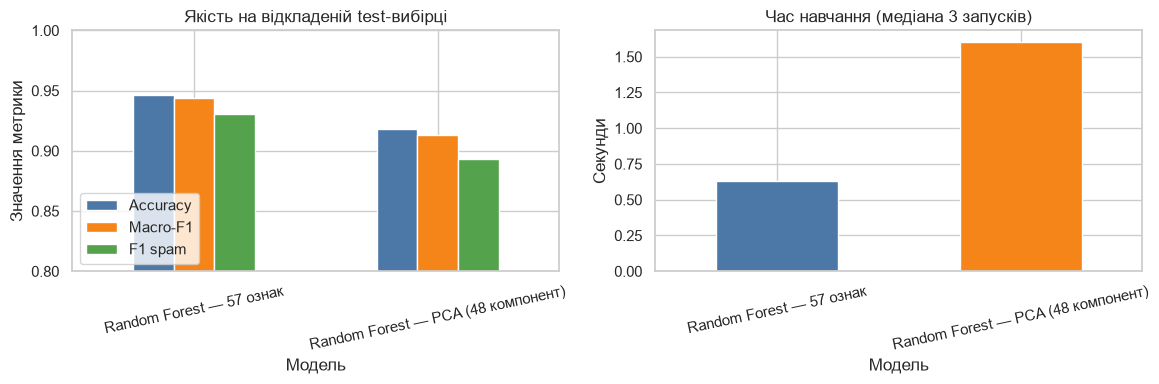

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pca_comparison[["Accuracy", "Macro-F1", "F1 spam"]].plot.bar(
    ax=axes[0], ylim=(0.80, 1.0), rot=12, color=["#4c78a8", "#f58518", "#54a24b"]
)
axes[0].set_title("Якість на відкладеній test-вибірці")
axes[0].set_ylabel("Значення метрики")
axes[0].legend(loc="lower left")

pca_comparison["Медіана fit, с"].plot.bar(
    ax=axes[1], rot=12, color=["#4c78a8", "#f58518"]
)
axes[1].set_title("Час навчання (медіана 3 запусків)")
axes[1].set_ylabel("Секунди")
plt.tight_layout()
plt.show()

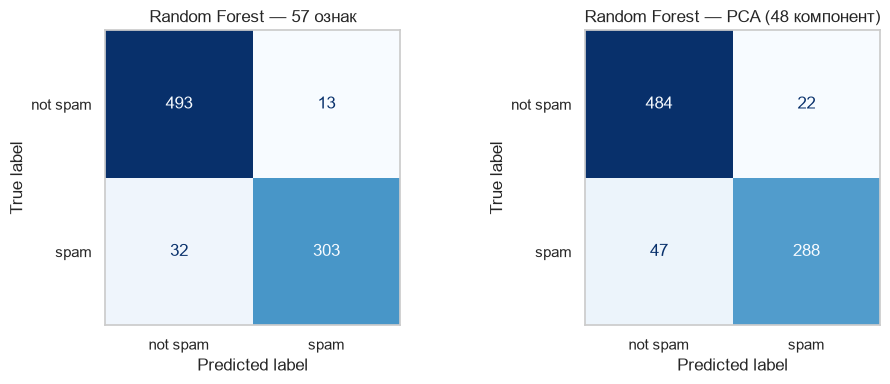


Random Forest — 57 ознак
              precision    recall  f1-score   support

    not spam     0.9390    0.9743    0.9564       506
        spam     0.9589    0.9045    0.9309       335

    accuracy                         0.9465       841
   macro avg     0.9490    0.9394    0.9436       841
weighted avg     0.9469    0.9465    0.9462       841


Random Forest — PCA (48 компонент)
              precision    recall  f1-score   support

    not spam     0.9115    0.9565    0.9335       506
        spam     0.9290    0.8597    0.8930       335

    accuracy                         0.9180       841
   macro avg     0.9203    0.9081    0.9132       841
weighted avg     0.9185    0.9180    0.9174       841



In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["not spam", "spam"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

for name, pred in predictions.items():
    print("\n" + name)
    print(classification_report(
        y_test, pred, labels=[0, 1],
        target_names=["not spam", "spam"], digits=4
    ))

**Висновок щодо PCA.** Кількість ознак зменшилася з 57 до 48, але macro-F1 впав з 0.9436 до 0.9132. Навчання також не прискорилося: разом із масштабуванням і PCA воно зайняло приблизно у 2.5 раза більше часу. Для цього датасету PCA не дав переваги. Метод зберігає найбільшу дисперсію, але не використовує мітки класів, тому частина корисної для класифікації інформації могла втратитися.

### 1.3. t-SNE до двох вимірів

t-SNE зменшує 57 ознак до двох координат і намагається зберегти локальне сусідство точок. Перед ним стандартизую дані. Мітки класів використовую тільки для кольору, а не для побудови координат.

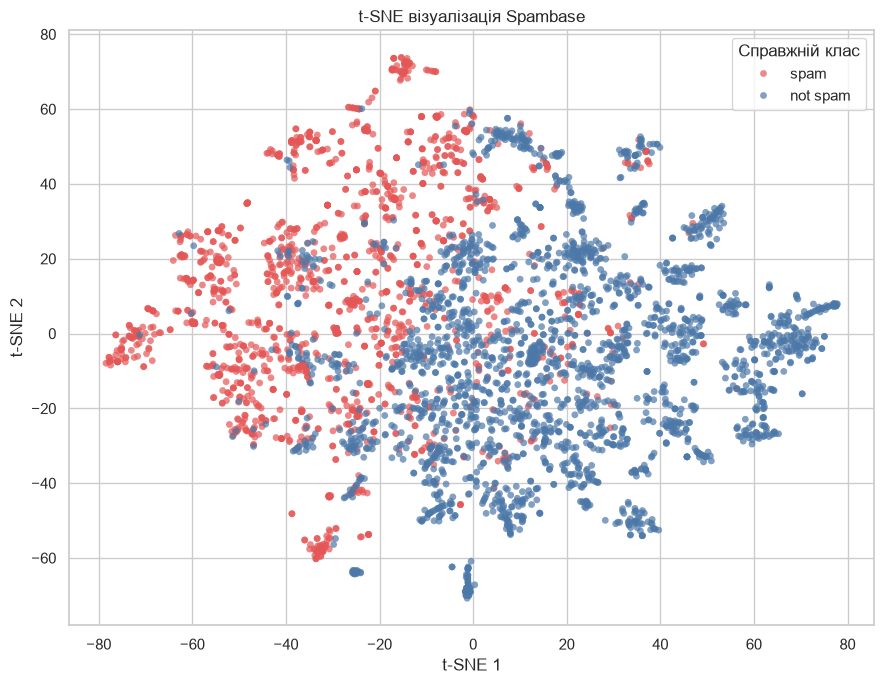

In [7]:
X_scaled_all = StandardScaler().fit_transform(X)
tsne = TSNE(
    n_components=2, perplexity=30, learning_rate="auto",
    init="pca", max_iter=1000, random_state=SEED
)
X_tsne = tsne.fit_transform(X_scaled_all)

tsne_df = pd.DataFrame({
    "t-SNE 1": X_tsne[:, 0],
    "t-SNE 2": X_tsne[:, 1],
    "Клас": y.map({0: "not spam", 1: "spam"}).to_numpy()
})

plt.figure(figsize=(9, 7))
sns.scatterplot(
    data=tsne_df, x="t-SNE 1", y="t-SNE 2", hue="Клас",
    palette={"not spam": "#4c78a8", "spam": "#e45756"},
    s=24, alpha=0.70, linewidth=0
)
plt.title("t-SNE візуалізація Spambase")
plt.legend(title="Справжній клас")
plt.tight_layout()
plt.show()

**Висновок щодо t-SNE.** На графіку є ділянки, де переважає один клас, але багато синіх і червоних точок змішані. Отже, ознаки допомагають відрізняти спам, проте класи не утворюють дві повністю відокремлені групи. Сам t-SNE використовую тільки для візуалізації.

## 2. Кластерний аналіз

### 2.1. Вибір кількості кластерів

K-Means отримує тільки стандартизовану матрицю `X`; `y` не передається в `fit`. Перевіряю `k=2...10`:

- **inertia (elbow method)** — сума квадратів відстаней до центроїдів; вона завжди зменшується, тому шукаємо місце, після якого виграш сповільнюється;
- **silhouette score** — порівнює близькість об'єкта до свого кластера з близькістю до інших; більше значення краще.

Silhouette рахую на фіксованій вибірці з 2000 об'єктів. Обираю `k` за найбільшим значенням, а elbow-графік використовую як додаткову перевірку.

,Inertia,Silhouette
k,,
2,223808.1838,0.6475
3,213866.8626,0.1176
4,206827.4055,0.1502
5,201785.9122,0.1395
6,197168.2634,0.1414
7,194021.8527,0.1472
8,190003.3059,0.0592
9,186863.0063,0.1010
10,182689.0368,0.0514


Найкраще k за silhouette: 2


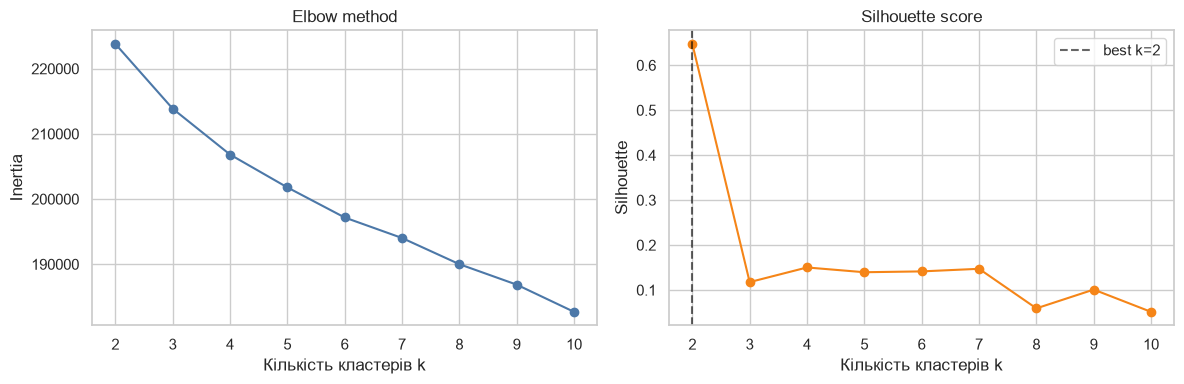

In [8]:
k_rows = []
models_by_k = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    cluster_labels_k = km.fit_predict(X_scaled_all)
    models_by_k[k] = (km, cluster_labels_k)
    k_rows.append({
        "k": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(
            X_scaled_all, cluster_labels_k, sample_size=2000, random_state=SEED
        )
    })

k_results = pd.DataFrame(k_rows).set_index("k")
best_k = int(k_results["Silhouette"].idxmax())
display(k_results.round(4))
print("Найкраще k за silhouette:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_results.index, k_results["Inertia"], "o-", color="#4c78a8")
axes[0].set(title="Elbow method", xlabel="Кількість кластерів k", ylabel="Inertia")
axes[0].set_xticks(k_results.index)
axes[1].plot(k_results.index, k_results["Silhouette"], "o-", color="#f58518")
axes[1].axvline(best_k, ls="--", color="black", alpha=0.6, label=f"best k={best_k}")
axes[1].set(title="Silhouette score", xlabel="Кількість кластерів k", ylabel="Silhouette")
axes[1].set_xticks(k_results.index)
axes[1].legend()
plt.tight_layout()
plt.show()

### 2.2. Візуалізація кластерів і порівняння з класами

Для 2D-візуалізації застосовую PCA до стандартизованих ознак. Номери кластерів довільні, тому напряму порівнювати `cluster 0` і `class 0` неправильно. Дивлюся на склад кластерів і три метрики:

- **ARI** (Adjusted Rand Index): 1 — повний збіг розбиттів, близько 0 — рівень випадкового збігу;
- **NMI** (Normalized Mutual Information): 1 — повна відповідність, 0 — незалежність;
- **purity**: частка об'єктів, що належать до домінуючого справжнього класу в кожному кластері. Purity може штучно зростати при великій кількості кластерів, тому не використовується для вибору `k` окремо.

In [9]:
kmeans_final, clusters = models_by_k[best_k]

ari = adjusted_rand_score(y, clusters)
nmi = normalized_mutual_info_score(y, clusters)
contingency = pd.crosstab(
    pd.Series(clusters, name="Кластер"),
    y.reset_index(drop=True).map({0: "not spam", 1: "spam"}),
    margins=True
)
contingency_no_margins = pd.crosstab(clusters, y.to_numpy())
purity = contingency_no_margins.max(axis=1).sum() / len(y)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")
print(f"Purity: {purity:.4f}")
display(contingency)

cluster_share = pd.crosstab(
    pd.Series(clusters, name="Кластер"),
    y.reset_index(drop=True).map({0: "not spam", 1: "spam"}),
    normalize="index"
)
display((cluster_share * 100).round(1).astype(str) + "%")

ARI: -0.0048
NMI: 0.0105
Purity: 0.6013


spam,not spam,spam,All
Кластер,,,
0,2497,1676,4173
1,31,0,31
All,2528,1676,4204


spam,not spam,spam
Кластер,,
0,59.8%,40.2%
1,100.0%,0.0%


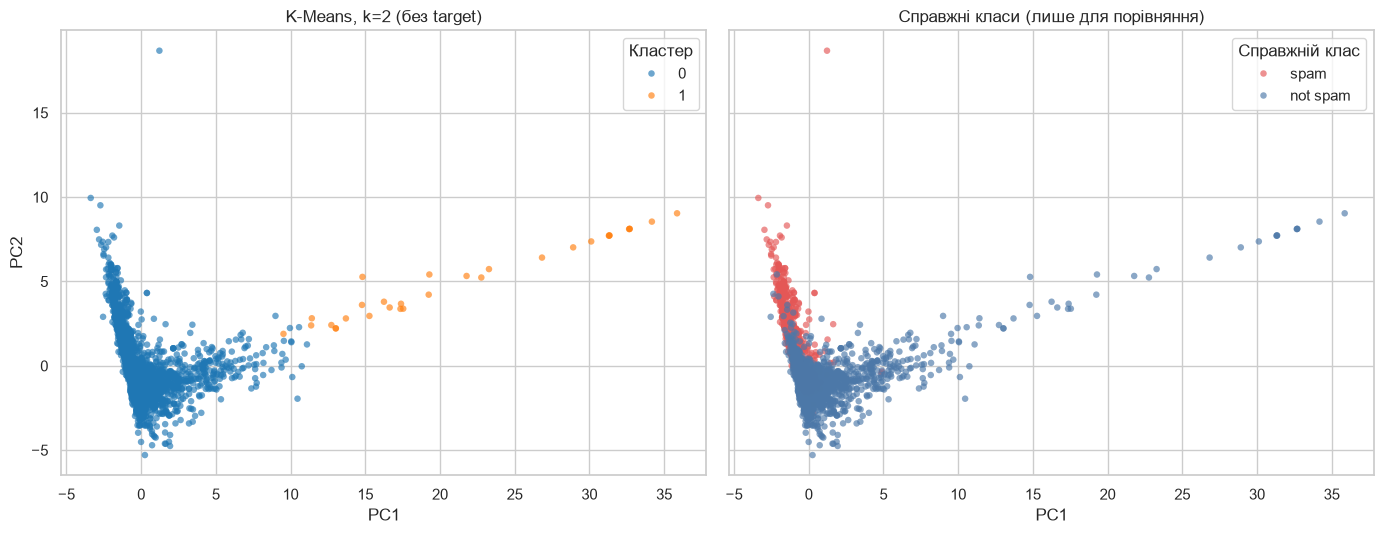

In [10]:
pca_2d = PCA(n_components=2, random_state=SEED)
X_pca_2d = pca_2d.fit_transform(X_scaled_all)
plot_df = pd.DataFrame({
    "PC1": X_pca_2d[:, 0],
    "PC2": X_pca_2d[:, 1],
    "Кластер": pd.Categorical(clusters.astype(str)),
    "Справжній клас": y.map({0: "not spam", 1: "spam"}).to_numpy()
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
sns.scatterplot(
    data=plot_df, x="PC1", y="PC2", hue="Кластер",
    palette="tab10", s=22, alpha=0.65, linewidth=0, ax=axes[0]
)
axes[0].set_title(f"K-Means, k={best_k} (без target)")
sns.scatterplot(
    data=plot_df, x="PC1", y="PC2", hue="Справжній клас",
    palette={"not spam": "#4c78a8", "spam": "#e45756"},
    s=22, alpha=0.65, linewidth=0, ax=axes[1]
)
axes[1].set_title("Справжні класи (лише для порівняння)")
plt.tight_layout()
plt.show()

In [11]:
print("Висновок щодо кластеризації")
print("-" * 35)
print(f"За silhouette обрано k={best_k}; silhouette={k_results.loc[best_k, 'Silhouette']:.4f}.")
print(f"Порівняння зі справжніми класами: ARI={ari:.4f}, NMI={nmi:.4f}, purity={purity:.4f}.")
if ari < 0.25:
    print("Збіг слабкий: геометричні кластери K-Means не відтворюють реальні класи spam/not spam.")
elif ari < 0.50:
    print("Збіг частковий: кластерна структура пов'язана з класами, але не повторює їх.")
else:
    print("Збіг помітний, але кластер і клас усе одно залишаються різними поняттями.")
print("Причина: K-Means мінімізує евклідові відстані до сферичних центроїдів, а не помилки класифікації;")
print("структуру також визначають масштаб, викиди та різні типи листів усередині кожного класу.")

Висновок щодо кластеризації
-----------------------------------
За silhouette обрано k=2; silhouette=0.6475.
Порівняння зі справжніми класами: ARI=-0.0048, NMI=0.0105, purity=0.6013.
Збіг слабкий: геометричні кластери K-Means не відтворюють реальні класи spam/not spam.
Причина: K-Means мінімізує евклідові відстані до сферичних центроїдів, а не помилки класифікації;
структуру також визначають масштаб, викиди та різні типи листів усередині кожного класу.


## 3. Обробка та класифікація текстових даних

### 3.1. SMS Spam Collection

Джерело: [UCI Machine Learning Repository — SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection), DOI: [10.24432/C5CC84](https://doi.org/10.24432/C5CC84). У файлі кожен рядок містить клас (`ham` або `spam`) і сирий текст SMS. Дані збережено в репозиторії, тому ноутбук не потребує завантаження з інтернету під час запуску.

Видаляю точні дублікати **до** train/test split, інакше однакове повідомлення могло б потрапити в обидві частини та завищити оцінку. Конфліктні тексти з різними мітками, якщо вони є, теж вилучаються.

In [12]:
sms_raw = pd.read_csv(
    SMS_PATH, sep="\t", header=None, names=["label", "text"],
    encoding="utf-8", quoting=3
)
print("Початковий розмір:", sms_raw.shape)
print("Пропусків:", int(sms_raw.isna().sum().sum()))
print("Точних дублікатів рядків:", int(sms_raw.duplicated().sum()))

sms = sms_raw.drop_duplicates().copy()
conflicting_text = sms.groupby("text")["label"].transform("nunique") > 1
print("Текстів із суперечливими мітками:", int(conflicting_text.sum()))
sms = sms.loc[~conflicting_text].drop_duplicates(subset="text").reset_index(drop=True)

print("Після очищення:", sms.shape)
display(sms.head())
sms_balance = pd.DataFrame({
    "Кількість": sms["label"].value_counts(),
    "Частка": sms["label"].value_counts(normalize=True)
})
sms_balance["Частка"] = (sms_balance["Частка"] * 100).round(1).astype(str) + "%"
display(sms_balance)

Початковий розмір: (5574, 2)
Пропусків: 0
Точних дублікатів рядків: 403
Текстів із суперечливими мітками: 0
Після очищення: (5171, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


,Кількість,Частка
label,,
ham,4518,87.4%
spam,653,12.6%


### 3.2. Передобробка та WordCloud

Функція нижче переводить текст у нижній регістр, замінює URL токеном `url`, числа — токеном `number`, а також прибирає пунктуацію і зайві пробіли. Англійські стоп-слова прибираються у TF-IDF і WordCloud.

`url` і `number` залишаю як окремі ознаки, тому що посилання та номери часто зустрічаються у спамі.

In [13]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"(?:https?://|www\.)\S+", " url ", text)
    text = re.sub(r"\b\d+(?:[.,]\d+)*\b", " number ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

sms["clean_text"] = sms["text"].map(clean_text)
display(sms[["label", "text", "clean_text"]].sample(5, random_state=SEED))

,label,text,clean_text
38,ham,Anything lor... U decide...,anything lor u decide
895,ham,"Call me da, i am waiting for your call.",call me da i am waiting for your call
4866,ham,"Nope, I'm still in the market",nope im still in the market
1413,ham,U sleeping now.. Or you going to take? Haha.. ...,u sleeping now or you going to take haha i got...
2460,ham,From 5 to 2 only my work timing.,from number to number only my work timing


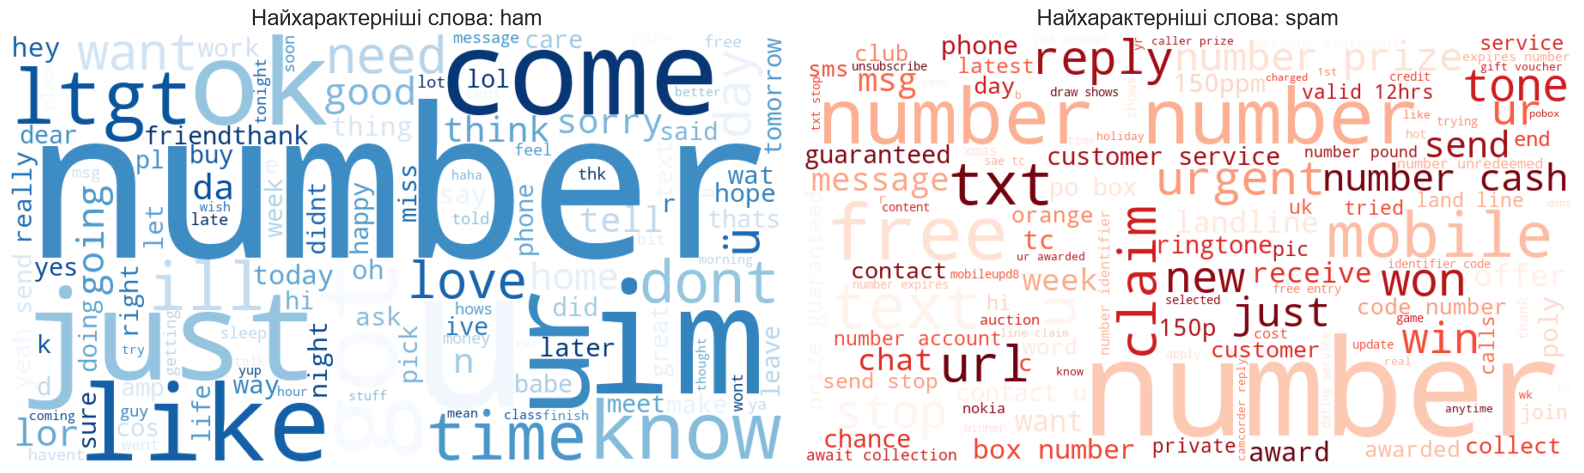

In [14]:
stop_words = set(ENGLISH_STOP_WORDS)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, label, cmap in zip(axes, ["ham", "spam"], ["Blues", "Reds"]):
    corpus = " ".join(sms.loc[sms["label"] == label, "clean_text"])
    cloud = WordCloud(
        width=900, height=500, background_color="white",
        stopwords=stop_words, colormap=cmap, collocations=True,
        max_words=120, random_state=SEED
    ).generate(corpus)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(f"Найхарактерніші слова: {label}", fontsize=16)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Висновок щодо WordCloud.** У `ham` частіше видно звичайні розмовні слова, наприклад `ok`, `come`, `home`, `later`. Для `spam` характерні `free`, `prize`, `claim`, `reply`, `mobile`, `txt`, а також `number` і `url`. Це відповідає змісту рекламних SMS. WordCloud показує частоту слів, але не враховує весь контекст повідомлення.

### 3.3. TF-IDF і Logistic Regression

Спочатку роблю stratified split. `TfidfVectorizer` знаходиться всередині `Pipeline`, тому словник та IDF будуються тільки на train. Використовую окремі слова і біграми, мінімальну частоту 2 документи та максимум 15 000 ознак. Для класифікації беру Logistic Regression з `class_weight="balanced"`.

Класів порівну немає, тому крім accuracy дивлюся на precision, recall і F1 для `spam`, macro-F1 та Average Precision.

In [15]:
X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    sms["clean_text"], sms["label"], test_size=0.20,
    stratify=sms["label"], random_state=SEED
)

text_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english", ngram_range=(1, 2), min_df=2,
        max_df=0.98, max_features=15000, sublinear_tf=True
    )),
    ("model", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=SEED
    ))
])
text_model.fit(X_text_train, y_text_train)
text_pred = text_model.predict(X_text_test)
text_prob_spam = text_model.predict_proba(X_text_test)[:, list(text_model.classes_).index("spam")]

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(np.zeros((len(y_text_train), 1)), y_text_train)
dummy_pred = dummy.predict(np.zeros((len(y_text_test), 1)))

text_results = pd.DataFrame([
    {
        "Модель": "Dummy: завжди ham",
        "Accuracy": accuracy_score(y_text_test, dummy_pred),
        "Macro-F1": f1_score(y_text_test, dummy_pred, average="macro"),
        "Precision spam": precision_score(y_text_test, dummy_pred, pos_label="spam", zero_division=0),
        "Recall spam": recall_score(y_text_test, dummy_pred, pos_label="spam", zero_division=0),
        "F1 spam": f1_score(y_text_test, dummy_pred, pos_label="spam", zero_division=0),
        "Average precision": np.nan,
    },
    {
        "Модель": "TF-IDF + Logistic Regression",
        "Accuracy": accuracy_score(y_text_test, text_pred),
        "Macro-F1": f1_score(y_text_test, text_pred, average="macro"),
        "Precision spam": precision_score(y_text_test, text_pred, pos_label="spam"),
        "Recall spam": recall_score(y_text_test, text_pred, pos_label="spam"),
        "F1 spam": f1_score(y_text_test, text_pred, pos_label="spam"),
        "Average precision": average_precision_score(
            (y_text_test == "spam").astype(int), text_prob_spam
        ),
    }
]).set_index("Модель")

display(text_results.round(4))
print(classification_report(y_text_test, text_pred, labels=["ham", "spam"], digits=4))

,Accuracy,Macro-F1,Precision spam,Recall spam,F1 spam,Average precision
Модель,,,,,,
Dummy: завжди ham,0.8734,0.4662,0.0000,0.0000,0.0000,NaN
TF-IDF + Logistic Regression,0.9768,0.9489,0.8849,0.9389,0.9111,0.9721


              precision    recall  f1-score   support

         ham     0.9911    0.9823    0.9867       904
        spam     0.8849    0.9389    0.9111       131

    accuracy                         0.9768      1035
   macro avg     0.9380    0.9606    0.9489      1035
weighted avg     0.9776    0.9768    0.9771      1035



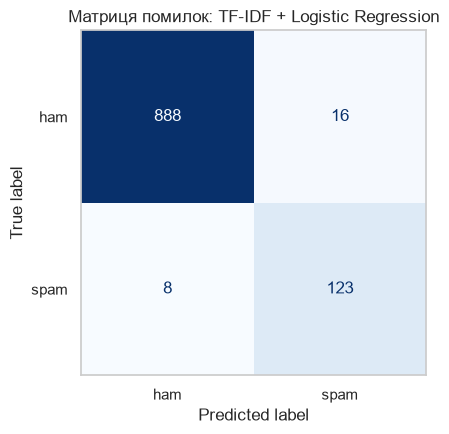

In [16]:
cm = confusion_matrix(y_text_test, text_pred, labels=["ham", "spam"])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set_title("Матриця помилок: TF-IDF + Logistic Regression")
ax.grid(False)
plt.tight_layout()
plt.show()

In [17]:
tfidf = text_model.named_steps["tfidf"]
classifier = text_model.named_steps["model"]
terms = np.array(tfidf.get_feature_names_out())
coef = classifier.coef_[0]  # додатний напрямок відповідає classifier.classes_[1]

top_n = 20
top_terms = pd.DataFrame({
    "ham (негативний коефіцієнт)": terms[np.argsort(coef)[:top_n]],
    "spam (позитивний коефіцієнт)": terms[np.argsort(coef)[-top_n:][::-1]],
})
print("Порядок класів моделі:", classifier.classes_)
display(top_terms)

Порядок класів моделі: ['ham' 'spam']


,ham (негативний коефіцієнт),spam (позитивний коефіцієнт)
0,ltgt,number
1,ok,url
2,im,txt
3,ill,mobile
4,hey,text
5,come,free
6,lor,reply
7,got,stop
8,da,claim
9,home,ringtone


## 4. Підсумкові висновки

1. PCA скоротив 57 ознак до 48, але macro-F1 Random Forest зменшився з 0.9436 до 0.9132. Час навчання зріс приблизно у 2.5 раза, тому для Spambase PCA не покращив результат.
2. На t-SNE видно часткове групування, але класи помітно перекриваються.
3. За silhouette обрано два кластери. Один із них містить лише 31 звичайний лист, а другий — майже всі дані. ARI = -0.0048 і NMI = 0.0105, тому знайдені кластери не відповідають класам `spam/not spam`.
4. Для SMS модель TF-IDF + Logistic Regression отримала accuracy 0.9768, macro-F1 0.9489 і F1 для спаму 0.9111. Dummy-модель мала високу accuracy через дисбаланс, але не знайшла жодного спам-повідомлення.